# 8. The margin theory of the size–volatility law

Notebooks 04–07 split a life's growth variance into a floor and a demographic part, with each life's measured field as
input. This notebook explains the law with one number per life: the **margin** $u=h/f$ of the firm's field $\Phi$ over
the life, with $h$ its mean and $f$ its standard deviation. The margin says how far the firm's market sits above the
level where the firm dies, in units of the market's own motion.

1. **Size is the market.** Integrating $d\ln S=[\Phi-S-D/(2S)]\,dt+\sqrt{D/S}\,dW$ over a life of length $T$ gives
   $\bar S=h-\tfrac D2\langle 1/S\rangle-\ln(S_{\rm end}/S_0)/T$ plus a noise term of mean zero. On the panel, a
   life's mean size is its mean field to a few per cent, except among the smallest lives.
2. **Volatility follows the margin.** The margin explains the volatility better than the size does. At fixed $u$ the
   size adds almost nothing on the power-law graph and a little on the regular graph, and $V(u)$ is nearly the same
   curve on both graphs.
3. **One firm in a Gaussian field gives $V(u)$.** Rescaling the field by $f$ rescales the size and leaves the growth
   rates nearly unchanged. The growth variance in one year depends on that year's field level $\psi=\Phi/f$: the
   firm follows its field where $\psi$ is large, lags where $\psi$ is small, and shrinks in dips. A Gaussian average
   over $\psi$ gives a closed law with no fitted constant. Its one-line form, the **simple law**, counts two kinds of
   years: calm years in which the firm follows its market, and dip years, a share $\Phi(-u)$ of the life, in which it
   moves with the field (end of section 4).
4. **The law on the panel.** With each life's $u$, $f$ and $n$, the law gives $\zeta_1$ and the ratio curve on both
   graphs. The margin carries the decline; the spread of $f$ at fixed $u$ carries the bend.
5. **Depth.** In 18 smaller economies at six depths, $\zeta_1$ is one curve in the median margin of established
   lives. The node field law (four constants and the field's correlation) gives that margin; the frozen fraction of
   sizes $q=Q_T/Q_0$ sets the frozen-to-moving ratio of the field; and the two-time closure predicts $q$ from $\mu$,
   $\sigma$, $D$ and the degrees. At the paper's reference point (section 5b) the closure's $q$ and median margin are
   within the scatter between economies, but its $\zeta_1$ is too steep and its curve hardly bends.

Volatility is the growth standard deviation (sd), except where the panel's MAD estimator is named. Lives have at least
20 growth rates unless stated. The reference economies are those of notebooks 04–07; the depth economies are new and
smaller ($N=8000$, window 240), and are cached in `data/demographic/margin`.

In [1]:
import sys
import numpy as np
import matplotlib.pyplot as plt
from joblib import Parallel, delayed
from scipy.interpolate import RegularGridInterpolator
import economy as eco
from economy import DATA, ROOT, D, DT, zeta_bins

import os
os.environ["PYTHONPATH"] = os.pathsep.join([str(ROOT / "notebooks"), str(ROOT / "scripts"),
                                            os.environ.get("PYTHONPATH", "")])   # for the joblib workers
MARGIN = DATA / "demographic" / "margin"
DEPTH = MARGIN / "depth"
DEPTH.mkdir(parents=True, exist_ok=True)
SIGMA_C = 1.497                      # instability line at mu = -1.76, D = 0.1, reference graph (notebook 02)
DEPTHS, DEPTH_SEEDS = (0.10, 0.15, 0.20, 0.25, 0.30, 0.40), (0, 1, 2)
MAXLAG = 120
f2 = lambda a: " ".join(f"{x:5.2f}" for x in a)
zeta = lambda Sb, x: zeta_bins(Sb, x)[0]


def mean_acf(x, T):
    """Network-mean autocorrelation of normalised paths x (rows), lags 0..MAXLAG-1 samples, cut at the first zero."""
    ac = np.array([np.mean(np.sum(x[:, l:] * x[:, :T - l], 1)) / T for l in range(MAXLAG)])
    ac /= ac[0]
    if (ac < 0).any():
        ac[np.argmax(ac < 0):] = 0
    return ac


def field_acf():
    """Autocorrelation of the normalised field of the first power-law reference economy (cache shared with 07)."""
    path = DATA / "demographic" / "floor" / "field_acf.npy"
    if not path.exists():
        path.parent.mkdir(parents=True, exist_ok=True)
        _, _, _, _, Phi = eco.reference_economy(eco.SEEDS[0])
        m, f = Phi.mean(1), Phi.std(1)
        np.save(path, mean_acf((Phi - m[:, None]) / f[:, None], Phi.shape[1]))
    return np.load(path)


def gauss_paths(acf, n, T, rng):
    """Stationary unit-variance Gaussian paths with autocorrelation acf (zero beyond its length), circulant embedding."""
    M = 2 * (T + len(acf))
    r = np.zeros(M); r[:len(acf)] = acf; r[M - len(acf) + 1:] = acf[1:][::-1]
    lam = np.clip(np.fft.rfft(r).real, 0, None)
    out = np.empty((n, T))
    for c0 in range(0, n, 4000):
        k = min(4000, n - c0)
        out[c0:c0 + k] = np.fft.irfft(np.fft.rfft(rng.standard_normal((k, M))) * np.sqrt(lam), n=M)[:, :T]
    return out / out.std()


def one_firm(Phi, S0, rng, dt=0.01):
    """dS = S(Phi - S)dt + sqrt(D S)dW along fields Phi (linear between samples), exit at 0, newborn at D."""
    N, T = Phi.shape
    per = int(round(DT / dt))
    S, life = S0.copy(), np.zeros(N, np.int64)
    oS, oL = np.empty((N, T), np.float32), np.empty((N, T), np.int64)
    oS[:, 0], oL[:, 0] = S, life
    for k in range(T - 1):
        for j in range(per):
            S = S + S * (Phi[:, k] + (Phi[:, k + 1] - Phi[:, k]) * j / per - S) * dt \
                + np.sqrt(D * np.maximum(S, 0) * dt) * rng.standard_normal(N)
            dead = S <= 0
            if dead.any():
                S[dead] = D; life[dead] += 1
        oS[:, k + 1], oL[:, k + 1] = S, life
    return oS, oL


def field_of(S, L, a):
    """Field Phi = 1 - aS - fbar, fbar with the entry dilution, as eco.reference_economy."""
    N = S.shape[0]
    aS = a @ S
    nu = np.diff(L, axis=1).sum(0) / (N * DT)
    return 1.0 - aS - (S * (1.0 - S - aS)).sum(0) / N - D * np.r_[nu, nu[-1]]


LIFE_COLS = ("Sbar", "v", "sd", "n", "h", "f", "born")


def life_table(S, L, Phi, nmin=5):
    """One row per life with >= nmin growth rates: mean size, the panel's MAD volatility, growth sd, n, mean and sd of
    the field over the life, and whether it was born inside the window."""
    T, rows = S.shape[1], []
    for i in range(S.shape[0]):
        for seg in np.split(np.arange(T), np.flatnonzero(np.diff(L[i])) + 1):
            if seg.size < nmin + 1:
                continue
            x = S[i, seg]; g = np.diff(np.log(x)); p = Phi[i, seg]
            rows.append((x.mean(), np.sqrt(np.pi / 2) * np.abs(g - g.mean()).mean(), g.std(), g.size, p.mean(), p.std(),
                         seg[0] > 0))
    return np.array(rows)


def cols(R):
    c = {k: R[:, j] for j, k in enumerate(LIFE_COLS[:R.shape[1]])}
    c["u"] = c["h"] / c["f"]
    return c


def vcurve(c, lo=-0.5, hi=2.76, step=0.25, nmin=20, key="sd"):
    """Growth sd of lives with >= nmin growth rates in bins of their margin u (bins with >= 100 lives)."""
    x, y = [], []
    for b in np.arange(lo, hi, step):
        m = (c["n"] >= nmin) & (c["u"] >= b) & (c["u"] < b + step)
        if m.sum() >= 100:
            x.append(b + step / 2); y.append(np.sqrt((c[key][m] ** 2).mean()))
    return np.array(x), np.array(y)

## 1. Size is the market

The two reference economies of each graph, lives with at least 20 growth rates, by decile of life-mean size: the mean
size and the mean field over the life. The two correction terms of the identity cannot be evaluated on yearly samples,
because $1/S$ is dominated by the moments near zero that the samples miss; they are small except among the smallest
lives.

In [2]:
def reference_lives(kind):
    path = MARGIN / f"lives_{kind}.npy"
    if not path.exists():
        R = []
        for seed in eco.SEEDS:
            S, L, deg, a, Phi = eco.reference_economy(seed, kind)
            R.append(life_table(S, L, Phi))
        np.save(path, np.concatenate(R))
    return cols(np.load(path))


PL, REG = reference_lives("powerlaw"), reference_lives("regular")
for name, c in (("power-law", PL), ("regular", REG)):
    m = c["n"] >= 20
    print(f"{name}: {m.sum()} lives.   Sbar    h")
    for p in np.array_split(np.argsort(c["Sbar"][m]), 10):
        print(f"            {c['Sbar'][m][p].mean():6.3f} {c['h'][m][p].mean():6.3f}")

power-law: 198840 lives.   Sbar    h
             0.254  0.142
             0.460  0.388
             0.630  0.573
             0.796  0.754
             0.973  0.939
             1.168  1.138
             1.400  1.378
             1.705  1.686
             2.169  2.155
             3.501  3.484
regular: 124498 lives.   Sbar    h
             0.208  0.077
             0.371  0.292
             0.513  0.455
             0.656  0.616
             0.811  0.787
             0.987  0.974
             1.194  1.190
             1.457  1.462
             1.856  1.870
             3.192  3.209


## 2. Volatility follows the margin

Least-squares fits of the log volatility on the size, the margin, the amplitude and the life length, and the binned
curve $V(u)$ on both graphs.

In [3]:
def fit(y, *X):
    A = np.c_[np.column_stack(X), np.ones(len(y))]
    c, res, *_ = np.linalg.lstsq(A, y, rcond=None)
    return c[:-1], 1 - res[0] / ((y - y.mean()) ** 2).sum()


for name, c in (("power-law", PL), ("regular", REG)):
    m = c["n"] >= 20
    y, lS, u, lf, ln = np.log(c["sd"][m]), np.log(c["Sbar"][m]), c["u"][m], np.log(c["f"][m]), np.log(c["n"][m])
    print(f"{name}, ln sd on:")
    for lab, X in (("ln Sbar", (lS,)), ("u", (u,)), ("ln Sbar, u", (lS, u)), ("u, ln f", (u, lf)),
                   ("ln Sbar, u, ln n", (lS, u, ln))):
        co, r2 = fit(y, *X)
        print(f"   {lab:17s} coefficients {f2(co)}   R2 {r2:.2f}")
x1, y1 = vcurve(PL); x2, y2 = vcurve(REG)
print("\n    u     V(u) power-law  regular")
for x in x1:
    print(f"  {x:+5.2f}      {y1[x1 == x][0]:.3f}       " + (f"{y2[x2 == x][0]:.3f}" if x in x2 else "  -"))

power-law, ln sd on:
   ln Sbar           coefficients -0.21   R2 0.20
   u                 coefficients -0.41   R2 0.46
   ln Sbar, u        coefficients  0.02 -0.43   R2 0.46


   u, ln f           coefficients -0.41  0.08   R2 0.47
   ln Sbar, u, ln n  coefficients  0.06 -0.27 -0.21   R2 0.57
regular, ln sd on:
   ln Sbar           coefficients -0.41   R2 0.52
   u                 coefficients -0.45   R2 0.61
   ln Sbar, u        coefficients -0.15 -0.32   R2 0.64
   u, ln f           coefficients -0.42 -0.17   R2 0.63
   ln Sbar, u, ln n  coefficients -0.06 -0.21 -0.21   R2 0.71

    u     V(u) power-law  regular
  -0.38      0.777       0.748
  -0.12      0.755       0.723
  +0.12      0.737       0.693
  +0.38      0.710       0.658
  +0.62      0.670       0.619
  +0.88      0.614       0.569
  +1.12      0.550       0.514
  +1.38      0.480       0.454
  +1.62      0.413       0.396
  +1.88      0.359       0.345
  +2.12      0.325       0.292
  +2.38      0.293       0.257
  +2.62      0.273       0.220
  +2.88      0.266       0.193


## 3. One firm in a Gaussian field

One firm per node, in the field $f(u_0+\xi)$, with $\xi$ of unit variance and the reference field's correlation, 1000
firms at each node margin $u_0$, at four amplitudes $f$. Lives are measured as in the panel, so their margin $u$ is
computed over the life, like the network's. The table compares $V(u)$ at the four amplitudes with the networks, and
the life-mean size per unit amplitude at each node margin.

In [4]:
U0, REP, BURN0, T0 = np.arange(-1.5, 3.51, 0.25), 1000, 100, 961
PB = np.arange(-3.0, 5.01, 0.125)


def fixed_margin(f, local=False):
    """Lives of one firm per node at node margin u0 (REP per u0) and amplitude f: rows (u0, Sbar, MAD v, n, h, f_life,
    sd, share of samples with Phi < 0).  local=True also returns, per u0 and bin of the year's field level psi, the
    count, sum of squared and of absolute growth deviations (lives >= 20)."""
    rows_path, loc_path = MARGIN / f"fixed_f{f}.npy", MARGIN / f"local_f{f}.npz"
    if not rows_path.exists() or (local and not loc_path.exists()):
        rng = np.random.default_rng(int(1000 * f + 17 * D + 3))
        uu = np.repeat(U0, REP)
        Phi = f * (uu[:, None] + gauss_paths(field_acf(), uu.size, BURN0 + T0, rng))
        S, L = one_firm(Phi, np.maximum(f * uu, D), rng)
        S, L, Phi = S[:, BURN0:].astype(float), L[:, BURN0:], Phi[:, BURN0:]
        rows, acc = [], np.zeros((U0.size, PB.size - 1, 3))
        for i in range(S.shape[0]):
            for seg in np.split(np.arange(T0), np.flatnonzero(np.diff(L[i])) + 1):
                if seg.size < 6:
                    continue
                x = S[i, seg]; g = np.diff(np.log(x)); p = Phi[i, seg]; dg = g - g.mean()
                rows.append((uu[i], x.mean(), np.sqrt(np.pi / 2) * np.abs(dg).mean(), g.size, p.mean(), p.std(), g.std(),
                             (p < 0).mean()))
                if seg.size >= 21:
                    psi = 0.5 * (p[:-1] + p[1:]) / f
                    b = np.clip(np.searchsorted(PB, psi) - 1, 0, PB.size - 2)
                    for j, val in enumerate((np.ones_like(dg), dg ** 2, np.abs(dg))):
                        np.add.at(acc[i // REP, :, j], b, val)
        np.save(rows_path, np.array(rows))
        np.savez(loc_path, acc=acc, PB=PB, US=U0)
    R = np.load(rows_path)
    c = {"u0": R[:, 0], "Sbar": R[:, 1], "v": R[:, 2], "n": R[:, 3], "h": R[:, 4], "f": R[:, 5], "sd": R[:, 6]}
    c["u"] = c["h"] / c["f"]
    return (c, np.load(loc_path)) if local else c


FS = (0.8, 1.2, 1.6, 2.4)
FIX = {f: fixed_margin(f) for f in FS}
curves = {f: vcurve(FIX[f]) for f in FS}
print("V(u) of lives >= 20:   u   " + "   ".join(f"f={f}" for f in FS) + "   power-law  regular")
for x in x1:
    row = f"                    {x:+5.2f} "
    for f in FS:
        cx, cy = curves[f]
        row += f"  {cy[cx == x][0]:.3f}" if x in cx else "    -  "
    print(row + f"     {y1[x1 == x][0]:.3f}    " + (f"{y2[x2 == x][0]:.3f}" if x in x2 else "  -"))
print("\nnode margin u0:   mean life size / f at f = " + " / ".join(str(f) for f in FS))
for u0 in np.arange(-0.5, 3.01, 0.5):
    print(f"   {u0:+.1f}        " + "   ".join(
        f"{FIX[f]['Sbar'][(FIX[f]['n'] >= 20) & np.isclose(FIX[f]['u0'], u0)].mean() / f:.3f}" for f in FS))

V(u) of lives >= 20:   u   f=0.8   f=1.2   f=1.6   f=2.4   power-law  regular
                    -0.38   0.748  0.762  0.784  0.790     0.777    0.748
                    -0.12   0.717  0.744  0.759  0.813     0.755    0.723
                    +0.12   0.685  0.708  0.722  0.777     0.737    0.693
                    +0.38   0.654  0.670  0.691  0.741     0.710    0.658
                    +0.62   0.622  0.630  0.644  0.699     0.670    0.619
                    +0.88   0.581  0.576  0.590  0.636     0.614    0.569
                    +1.12   0.536  0.519  0.524  0.559     0.550    0.514
                    +1.38   0.486  0.452  0.449  0.478     0.480    0.454
                    +1.62   0.431  0.389  0.379  0.397     0.413    0.396
                    +1.88   0.381  0.332  0.320  0.333     0.359    0.345
                    +2.12   0.336  0.279  0.267  0.279     0.325    0.292
                    +2.38   0.287  0.237  0.229  0.234     0.293    0.257
                    +2.62   0.256 

**The local law.** Each year of a life has a field level $\psi=\Phi/f$. Binned by $\psi$, the growth variance (around the
life's mean growth) is the same for every node margin $u_0$ in dips ($\psi<0$, where the firm shrinks at the field's
rate, $g\simeq f\Delta t\,\psi$, plus granular noise) and on high plateaus ($\psi\gtrsim2.5$, where the firm follows its
field and $g\simeq\Delta\psi/\psi$). In between the firm remembers its past: one that climbs back from a dip is more
volatile than one that came down from higher.

In [5]:
for f in (1.2, 2.4):
    _, loc = fixed_margin(f, local=True)
    acc, c = loc["acc"], 0.5 * (PB[1:] + PB[:-1])
    pick = [i for i, u in enumerate(U0) if abs(2 * u - round(2 * u)) < 1e-9 and -1 <= u <= 3]
    print(f"f = {f}: growth sd by field level psi (rows) and node margin u0 (columns), lives >= 20")
    print("    psi " + "".join(f"  {U0[i]:+5.1f}" for i in pick))
    for j in range(0, c.size, 4):
        sl = slice(j, j + 4)
        if acc[:, sl, 0].sum() < 200:
            continue
        print(f"  {c[sl].mean():+5.2f} " + "".join(
            f"  {np.sqrt(acc[i, sl, 1].sum() / acc[i, sl, 0].sum()):5.3f}" if acc[i, sl, 0].sum() > 200 else "     - "
            for i in pick))

f = 1.2: growth sd by field level psi (rows) and node margin u0 (columns), lives >= 20
    psi    -1.0   -0.5   +0.0   +0.5   +1.0   +1.5   +2.0   +2.5   +3.0
  -2.25      -      -      -      -      -      -      -      -      - 
  -1.75   1.550  1.484  1.578  1.495  1.564     -      -      -      - 
  -1.25   1.270  1.280  1.280  1.333  1.306  1.299  1.334     -      - 
  -0.75   0.961  0.994  1.009  1.015  1.034  1.013  0.984  0.933     - 
  -0.25   0.709  0.721  0.727  0.724  0.733  0.721  0.709  0.671  0.617
  +0.25   0.557  0.537  0.537  0.521  0.497  0.488  0.468  0.435  0.405
  +0.75   0.511  0.469  0.445  0.416  0.378  0.350  0.318  0.300  0.285
  +1.25   0.497  0.465  0.423  0.376  0.325  0.288  0.254  0.232  0.219
  +1.75   0.511  0.465  0.406  0.346  0.290  0.246  0.215  0.194  0.183
  +2.25   0.466  0.413  0.357  0.302  0.243  0.207  0.179  0.163  0.153
  +2.75      -   0.350  0.295  0.241  0.197  0.166  0.147  0.137  0.130
  +3.25      -      -   0.227  0.193  0.151  0.13

**The closed law.** On a high plateau the firm sits at $S\simeq f\psi$, so its growth is the relative change of its
market plus the granular noise at that size: $\sigma^2=A/\psi^2$ with $A=r^2+D/f^2$ and $r^2=2[1-\rho(\Delta t)]$, the
field's relative change over a year. The firm relaxes at the rate $S=f\psi$, while its target $\ln(f\psi)$ moves at
the rate $\dot\psi/\psi$, so it follows only where $f\psi^2>\dot\psi_{\rm rms}$; this sets the lag cutoff
$\psi_c^2=\dot\psi_{\rm rms}/f$, with $\dot\psi_{\rm rms}=r/\Delta t$. In a dip the firm is decoupled and shrinks at the
field's rate. So
$$\sigma^2_{\rm loc}(\psi)=\begin{cases}A/(\psi^2+\psi_c^2), & \psi\ge0,\\ A/\psi_c^2+(f\Delta t\,\psi)^2, & \psi<0,\end{cases}
\qquad V^2_{\rm stat}(u)=\mathbb E\big[\sigma^2_{\rm loc}(\psi)\big],\ \psi\sim N(u,1).$$
Over a life, $\psi$ has mean $u$ and variance 1 by definition of $u$. A life also begins with a climb from $D$ towards
its target; for a logistic climb to $h$, the squared growth summed over the climb is
$E_{\rm in}\simeq\Delta t\,h[\ln(h/D)-1]$, plus $1/h$ from the noise, spread over the life's $n$ years. With $h=\bar S$,
$$v^2\simeq V^2_{\rm stat}(u,f)+E_{\rm in}(\bar S)/n .$$
Only $r^2$ is taken from simulation (the field's correlation at one year); nothing is fitted. At large $u$ the law
tends to $(r^2+D/f^2)/u^2$: the only dependence on $f$ left is the granular term $D/f^2$, which gives the dependence on
$f$ at $u_0=3$ to within a few per cent.

In [6]:
ACF = field_acf()
R2 = 2 * (1 - ACF[1]); PDOT = np.sqrt(R2) / DT
PS = np.linspace(-8, 12, 4001); DPS = PS[1] - PS[0]


def V2(u, f):
    """Stationary closed law: Gaussian average over the life's field level psi ~ N(u, 1) of the local variance."""
    pc2, A = PDOT / f, R2 + D / f ** 2
    loc = np.where(PS < 0, A / pc2 + (f * DT * PS) ** 2, A / (PS ** 2 + pc2))
    return (np.exp(-0.5 * (PS - u) ** 2) * loc).sum() * DPS / np.sqrt(2 * np.pi)


GU, GF = np.linspace(-3, 5, 161), np.linspace(0.2, 4, 39)
VTAB = RegularGridInterpolator((GU, GF), np.array([[V2(x, y) for y in GF] for x in GU]), bounds_error=False,
                               fill_value=None)
V2_life = lambda u, f: VTAB(np.c_[np.clip(u, -3, 5), np.clip(f, 0.2, 4)])
E_in = lambda h: np.maximum(DT * np.maximum(h, 1e-3) * (np.log(np.maximum(h, 1e-3) / D) - 1), 0) + 1 / np.maximum(h, 1e-3)

print(f"r^2 = {R2:.4f}, psidot_rms = {PDOT:.3f}")
print("lives >= 20, growth sd by life margin u: one firm (f = 1.2) against the stationary law at the bin's mean f_life")
for x in np.arange(-0.125, 2.7, 0.25):
    c = FIX[1.2]; m = (c["n"] >= 20) & (np.abs(c["u"] - x) < 0.125)
    print(f"   {x:+5.2f}   one firm {np.sqrt((c['sd'][m] ** 2).mean()):.3f}   law {np.sqrt(V2(x, c['f'][m].mean())):.3f}")
print("\nnode margin u0 = 3: sd at f = 0.8, 1.6, 2.4 over f = 1.2, measured / large-u law")
c12 = FIX[1.2]; ref = np.sqrt((c12["sd"][(c12["n"] >= 20) & np.isclose(c12["u0"], 3)] ** 2).mean())
for f in (0.8, 1.6, 2.4):
    c = FIX[f]; m = (c["n"] >= 20) & np.isclose(c["u0"], 3)
    pred = np.sqrt((R2 + D / f ** 2 * (1 - np.exp(-f * 3 * DT))) / (R2 + D / 1.44 * (1 - np.exp(-3.6 * DT))))
    print(f"   f = {f}: {np.sqrt((c['sd'][m] ** 2).mean()) / ref:.3f} / {pred:.3f}")

r^2 = 0.1021, psidot_rms = 0.639
lives >= 20, growth sd by life margin u: one firm (f = 1.2) against the stationary law at the bin's mean f_life
   -0.12   one firm 0.744   law 0.603
   +0.12   one firm 0.708   law 0.565
   +0.38   one firm 0.670   law 0.524
   +0.62   one firm 0.630   law 0.481
   +0.88   one firm 0.576   law 0.440
   +1.12   one firm 0.519   law 0.399
   +1.38   one firm 0.452   law 0.359
   +1.62   one firm 0.389   law 0.321
   +1.88   one firm 0.332   law 0.285
   +2.12   one firm 0.279   law 0.252
   +2.38   one firm 0.237   law 0.224
   +2.62   one firm 0.205   law 0.198

node margin u0 = 3: sd at f = 0.8, 1.6, 2.4 over f = 1.2, measured / large-u law
   f = 0.8: 1.175 / 1.149
   f = 1.6: 0.962 / 0.927
   f = 2.4: 0.934 / 0.862


## 4. The law on the panel

Each life's volatility replaced by the law at its own $u$, $f$, $\bar S$ and $n$ (the birth term only for lives born in
the window), then binned like the panel. Switching ingredients on one at a time: the margin alone (amplitude at its
mean), plus each life's own amplitude, plus birth.

In [7]:
for name, c in (("power-law", PL), ("regular", REG)):
    m = c["n"] >= 20
    Sb, sd, n, f, u, born = (c[k][m] for k in ("Sbar", "sd", "n", "f", "u", "born"))
    fbar = np.exp(np.log(f).mean())
    stat_u, stat = V2_life(u, np.full(u.size, fbar)), V2_life(u, f)
    full = stat + np.where(born > 0, E_in(Sb), 0) / n
    print(f"{name}, lives >= 20, sd (zeta_1, then zeta_q / zeta_1):")
    for lab, x in (("simulation", sd ** 2), ("margin only", stat_u), ("+ own amplitude", stat), ("+ birth", full)):
        z = zeta(Sb, np.sqrt(x))
        print(f"   {lab:16s} {z[0]:.3f}   {f2(z[1:] / z[0])}")
    print(f"   per-life log correlation, law against simulation: {np.corrcoef(np.log(sd), 0.5 * np.log(full))[0, 1]:.2f}")

power-law, lives >= 20, sd (zeta_1, then zeta_q / zeta_1):
   simulation       0.190    1.75  2.30  2.70
   margin only      0.237    1.96  2.90  3.84
   + own amplitude  0.176    1.71  2.15  2.34


   + birth          0.195    1.73  2.23  2.52
   per-life log correlation, law against simulation: 0.76
regular, lives >= 20, sd (zeta_1, then zeta_q / zeta_1):
   simulation       0.397    1.93  2.78  3.53


   margin only      0.289    1.97  2.91  3.84
   + own amplitude  0.330    1.94  2.81  3.61
   + birth          0.379    1.93  2.78  3.57
   per-life log correlation, law against simulation: 0.83


**The simple law.** The mechanism fits in one line. A year is of one of two kinds. In a calm year the market is well
above zero and the firm follows it, with the growth variance $A/(u^2+\psi_c^2)$ of the tracking regime. In a dip year
the market is below zero; the firm cannot follow it, and it moves with the field itself, by $f\Delta t$ in a year, on
top of the noise at the lag level. A life of margin $u$ has a share $\Phi(-u)$ of dip years, so
$$v^2\simeq\Phi(-u)\Big[\frac{A}{\psi_c^2}+(f\Delta t)^2\Big]+\Phi(u)\,\frac{A}{u^2+\psi_c^2},\qquad A=r^2+\frac D{f^2},\quad
\psi_c^2=\frac{\dot\psi_{\rm rms}}f .$$
A large margin means few dip years, so the firm is calm. The table compares it with the simulation and the full law
of section 3 (stationary part, no birth term). The simple law gets the decline and the shape of the levels on both
graphs (about 10–15% low throughout) and the ratio curve on the regular graph. On the power-law graph it overstates the
bend, so there the bend is read from the criterion of section 4, not from this formula. Giving each dip its Gaussian
depth instead of the full shrink weakens the over-bend but spoils the decline (last line).

In [8]:
from scipy.stats import norm


def simple_law(u, f, depth=False):
    """Two kinds of years: dips (share Phi(-u)) move with the field, calm years follow the market."""
    A, pc2 = R2 + D / f ** 2, PDOT / f
    dip = (1 + u ** 2) * norm.cdf(-u) - u * norm.pdf(u) if depth else norm.cdf(-u)
    return norm.cdf(-u) * A / pc2 + (f * DT) ** 2 * dip + norm.cdf(u) * A / (u ** 2 + pc2)


for name, c in (("power-law", PL), ("regular", REG)):
    m = c["n"] >= 20
    Sb, sd, u, f = c["Sbar"][m], c["sd"][m], c["u"][m], c["f"][m]
    print(f"{name}, lives >= 20, sd:            zeta_1  ratios              level / simulation by size fifth")
    for lab, x in (("simulation", sd ** 2), ("simple law", simple_law(u, f)), ("full law, stationary part", V2_life(u, f)),
                   ("simple law, Gaussian dip depth", simple_law(u, f, depth=True))):
        z = zeta(Sb, np.sqrt(x))
        lv = [np.sqrt(x[p].mean() / (sd[p] ** 2).mean()) for p in np.array_split(np.argsort(Sb), 5)]
        print(f"   {lab:31s} {z[0]:.3f}  {f2(z[1:] / z[0])}   {f2(lv)}")

power-law, lives >= 20, sd:            zeta_1  ratios              level / simulation by size fifth
   simulation                      0.190   1.75  2.30  2.70    1.00  1.00  1.00  1.00  1.00
   simple law                      0.180   1.50  1.57  1.28    0.87  0.87  0.86  0.87  0.93


   full law, stationary part       0.176   1.71  2.15  2.34    0.80  0.79  0.79  0.81  0.83
   simple law, Gaussian dip depth  0.253   1.70  2.10  2.25    0.86  0.84  0.80  0.78  0.77
regular, lives >= 20, sd:            zeta_1  ratios              level / simulation by size fifth
   simulation                      0.397   1.93  2.78  3.53    1.00  1.00  1.00  1.00  1.00
   simple law                      0.393   1.90  2.68  3.33    0.88  0.89  0.86  0.85  0.89


   full law, stationary part       0.330   1.94  2.81  3.61    0.82  0.82  0.81  0.84  0.92
   simple law, Gaussian dip depth  0.427   1.94  2.80  3.58    0.88  0.87  0.82  0.80  0.81


## 5. Depth

Six depths $\sigma-\sigma_c$ at $\mu=-1.76$, $D=0.1$, power-law graph, three economies each ($N=8000$, $C=200$, burn-in
100, window 240; about 45 s each). The closed law, with the reference $r^2$, follows $\zeta_1$ at every depth. Freezing
the amplitude at one value in the law keeps most of the trend, so depth acts through the margins of the lives, and the
margins move down with depth: the upper tail empties.

In [9]:
def depth_economy(d, seed, N=8000):
    path = DEPTH / f"d{d:.2f}_s{seed}.npz"
    if not path.exists():
        a = eco.configuration_coupling(N, eco.MU, SIGMA_C + d, alpha=eco.ALPHA, mean_degree=eco.C, seed=seed)
        r = eco.integrate_demographic(a, D=D, tmax=340.0, t_start=100.0, dt_save=DT, seed=seed, compact=True)
        np.savez_compressed(path, S=r["S"], L=r["life"], deg=np.diff(a.indptr), sigma=SIGMA_C + d, seed=seed, N=N)
    return path


def load_depth(d, seed):
    z = np.load(depth_economy(d, seed))
    S, L, N = z["S"].astype(float), z["L"], int(z["N"])
    a = eco.configuration_coupling(N, eco.MU, float(z["sigma"]), alpha=eco.ALPHA, mean_degree=eco.C, seed=int(z["seed"]))
    assert np.array_equal(np.diff(a.indptr), z["deg"])
    return S, L, z["deg"], a, field_of(S, L, a)


def depth_lives(d, seed):
    path = DEPTH / f"lives_d{d:.2f}_s{seed}.npy"
    if not path.exists():
        S, L, _, _, Phi = load_depth(d, seed)
        np.save(path, life_table(S, L, Phi))
    return path


RUNS = [(d, s) for d in DEPTHS for s in DEPTH_SEEDS]
Parallel(n_jobs=-1)(delayed(depth_economy)(d, s) for d, s in RUNS)
Parallel(n_jobs=-1)(delayed(depth_lives)(d, s) for d, s in RUNS)
LV = {(d, s): cols(np.load(depth_lives(d, s))) for d, s in RUNS}

FREF = 0.91
print("depth | zeta_1 (>= 20, sd): sim  law  law at f = 0.91 | margin of lives >= 20: 10/50/90%  | median f")
for d in DEPTHS:
    z = []
    for s in DEPTH_SEEDS:
        c = LV[d, s]; m = c["n"] >= 20
        Sb, sd, n, f, u, born = (c[k][m] for k in ("Sbar", "sd", "n", "f", "u", "born"))
        bt = np.where(born > 0, E_in(Sb), 0) / n
        z.append([zeta(Sb, sd)[0], zeta(Sb, np.sqrt(V2_life(u, f) + bt))[0], zeta(Sb, np.sqrt(V2_life(u, np.full(u.size, FREF)) + bt))[0]])
    uu = np.concatenate([LV[d, s]["u"][LV[d, s]["n"] >= 20] for s in DEPTH_SEEDS])
    ff = np.concatenate([LV[d, s]["f"][LV[d, s]["n"] >= 20] for s in DEPTH_SEEDS])
    z = np.mean(z, 0)
    print(f" {d:.2f} |   {z[0]:+.3f} {z[1]:+.3f}   {z[2]:+.3f}            |  {f2(np.percentile(uu, [10, 50, 90]))}   |  {np.median(ff):.2f}")

depth | zeta_1 (>= 20, sd): sim  law  law at f = 0.91 | margin of lives >= 20: 10/50/90%  | median f
 0.10 |   +0.486 +0.491   +0.490            |   0.25  1.31  3.28   |  0.52
 0.15 |   +0.420 +0.433   +0.413            |   0.25  1.13  2.56   |  0.67
 0.20 |   +0.307 +0.313   +0.310            |   0.28  1.00  2.06   |  0.91


 0.25 |   +0.186 +0.185   +0.211            |   0.31  0.91  1.70   |  1.24
 0.30 |   +0.108 +0.099   +0.148            |   0.32  0.83  1.48   |  1.62
 0.40 |   -0.001 +0.006   +0.044            |   0.32  0.75  1.25   |  2.38


**One number sets $\zeta_1$.** Run by run, $\zeta_1$ of the panel against the median margin of the run's established
lives (at least 20 growth rates), with a quadratic fit; against depth for comparison.

In [10]:
RUN = []
for d, s in RUNS:
    c = LV[d, s]; m5, m = c["n"] >= 5, c["n"] >= 20
    RUN.append((d, s, np.median(c["u"][m]), zeta(c["Sbar"][m5], c["v"][m5])[0], zeta(c["Sbar"][m], c["sd"][m])[0]))
RUN = np.array(RUN)
for j, lab in ((3, "panel >= 5, MAD"), (4, "lives >= 20, sd")):
    cu = np.polyfit(RUN[:, 2], RUN[:, j], 2); cd = np.polyfit(RUN[:, 0], RUN[:, j], 1)
    print(f"zeta_1 ({lab}): residual sd on the median margin (quadratic) {np.std(RUN[:, j] - np.polyval(cu, RUN[:, 2])):.3f},"
          f" on depth (linear) {np.std(RUN[:, j] - np.polyval(cd, RUN[:, 0])):.3f}")
cu = np.polyfit(RUN[:, 2], RUN[:, 3], 2)
print(f"zeta_1 = 0.20 (panel) at median margin {[r.real for r in np.roots(cu - [0, 0, 0.2]) if 0.5 < r.real < 1.5][0]:.2f}")

zeta_1 (panel >= 5, MAD): residual sd on the median margin (quadratic) 0.010, on depth (linear) 0.035
zeta_1 (lives >= 20, sd): residual sd on the median margin (quadratic) 0.028, on depth (linear) 0.059
zeta_1 = 0.20 (panel) at median margin 0.93


**From the node law to the panel.** A node's field has a mean $a_0-b\kappa$, a frozen spread $s\sqrt\kappa$ at equal
degree and a moving amplitude $c\sqrt\kappa$. One firm per real node, driven by a Gaussian field with these four
constants and the run's own field correlation ("law"), or with each node's own mean and amplitude ("nodes"), predicts
the run's margins and exponents. Lives see only their own stretch of the field, so a node's margin is not a life's
margin; the one-firm step does that mapping. The constants follow from the sizes: $s^2=\sigma^2Q_T$ and
$c^2=\sigma^2(Q_0-Q_T)$, with $Q_0$ and $Q_T$ the degree-weighted total and frozen (window-mean) second moments of
the sizes. So the frozen-to-moving ratio of the field is set by the frozen fraction of sizes $q=Q_T/Q_0$.

In [11]:
def node_law(d, seed):
    """One firm per node: field from each node's own mean and amplitude ("nodes") or from the four-constant law
    ("law"), with the run's own field autocorrelation; burn-in 200 samples, then the run's window."""
    path = DEPTH / f"nodelaw_d{d:.2f}_s{seed}.npz"
    if not path.exists():
        S, L, deg, _, Phi = load_depth(d, seed)
        N, T = S.shape
        kap = deg / deg.mean(); m, f = Phi.mean(1), Phi.std(1)
        acf = mean_acf((Phi - m[:, None]) / f[:, None], T)
        (a0, a1), *_ = np.linalg.lstsq(np.c_[np.ones(N), kap], m, rcond=None)
        s = np.sqrt(np.mean((m - a0 - a1 * kap) ** 2 / kap)); c = np.exp(np.mean(np.log(f) - 0.5 * np.log(kap)))
        rng = np.random.default_rng(seed + 77)
        out = dict(a0=a0, a1=a1, s=s, c=c, acf=acf)
        for name, mm, ff in (("nodes", m, f), ("law", a0 + a1 * kap + s * np.sqrt(kap) * rng.standard_normal(N), c * np.sqrt(kap))):
            F = mm[:, None] + ff[:, None] * gauss_paths(acf, N, 200 + T, rng)
            Ss, Ls = one_firm(F, np.maximum(mm, D), rng)
            out[name] = life_table(Ss[:, 200:].astype(float), Ls[:, 200:], F[:, 200:])
        np.savez(path, **out)
    return path


def frozen_fraction(d, seed):
    """Degree-weighted Q_0 = <S^2> and Q_T = <(window-mean S)^2> of a depth economy."""
    z = np.load(depth_economy(d, seed))
    S, w = z["S"].astype(float), z["deg"] / z["deg"].sum()
    return (w * (S ** 2).mean(1)).sum(), (w * S.mean(1) ** 2).sum(), float(z["sigma"])


Parallel(n_jobs=-1)(delayed(node_law)(d, s) for d, s in RUNS)
NL, rows = {}, []
print("run      | s: meas  sigma sqrt(Q_T) | c: meas  sigma sqrt(Q0-Q_T) | q     | u_med: net  law  | zeta_1 panel: net  nodes  law")
for i, (d, s) in enumerate(RUNS):
    z = NL[d, s] = np.load(node_law(d, s))
    Q0, QT, sig = frozen_fraction(d, s)
    nd, lw = cols(z["nodes"]), cols(z["law"])
    zp = [zeta(c["Sbar"][c["n"] >= 5], c["v"][c["n"] >= 5])[0] for c in (nd, lw)]
    ul = np.median(lw["u"][lw["n"] >= 20])
    rows.append((d, s, QT / Q0, ul, zp[0], zp[1]))
    print(f"{d:.2f} s{s}  |  {float(z['s']):.2f}   {sig * np.sqrt(QT):.2f}           |  {float(z['c']):.2f}   {sig * np.sqrt(Q0 - QT):.2f}"
          f"            | {QT / Q0:.3f} |  {RUN[i, 2]:.2f}  {ul:.2f}  |  {RUN[i, 3]:+.3f}  {zp[0]:+.3f}  {zp[1]:+.3f}")
NLR = np.array(rows)
for j, lab, k in ((3, "u_med", 2), (4, "zeta_1 nodes", 3), (5, "zeta_1 law", 3)):
    e = NLR[:, j] - RUN[:, k]
    print(f"{lab:13s}: bias {e.mean():+.3f}, rms {np.sqrt((e ** 2).mean()):.3f}, correlation {np.corrcoef(NLR[:, j], RUN[:, k])[0, 1]:.2f}")

run      | s: meas  sigma sqrt(Q_T) | c: meas  sigma sqrt(Q0-Q_T) | q     | u_med: net  law  | zeta_1 panel: net  nodes  law
0.10 s0  |  2.59   2.56           |  0.82   0.90            | 0.891 |  1.24  1.20  |  +0.370  +0.365  +0.388


0.10 s1  |  2.32   2.33           |  1.01   1.08            | 0.822 |  1.37  1.27  |  +0.383  +0.365  +0.386


0.10 s2  |  2.40   2.42           |  0.70   0.74            | 0.914 |  1.31  1.27  |  +0.393  +0.392  +0.400
0.15 s0  |  2.80   2.76           |  1.18   1.28            | 0.823 |  1.10  1.07  |  +0.318  +0.312  +0.334


0.15 s1  |  2.53   2.53           |  1.03   1.10            | 0.842 |  1.14  1.12  |  +0.344  +0.338  +0.357


0.15 s2  |  2.55   2.56           |  1.01   1.08            | 0.850 |  1.14  1.11  |  +0.347  +0.341  +0.354
0.20 s0  |  3.04   2.99           |  1.84   1.97            | 0.698 |  0.94  0.89  |  +0.202  +0.189  +0.212


0.20 s1  |  2.72   2.72           |  1.27   1.34            | 0.805 |  1.06  1.02  |  +0.306  +0.298  +0.312


0.20 s2  |  2.74   2.75           |  1.33   1.43            | 0.787 |  1.03  0.98  |  +0.296  +0.280  +0.301
0.25 s0  |  3.24   3.19           |  2.40   2.53            | 0.614 |  0.85  0.82  |  +0.130  +0.122  +0.142


0.25 s1  |  2.79   2.78           |  2.12   2.23            | 0.609 |  0.92  0.88  |  +0.189  +0.171  +0.192
0.25 s2  |  2.81   2.82           |  1.75   1.84            | 0.702 |  0.98  0.93  |  +0.235  +0.230  +0.244


0.30 s0  |  3.26   3.21           |  3.27   3.34            | 0.480 |  0.78  0.76  |  +0.059  +0.049  +0.068
0.30 s1  |  3.02   3.01           |  2.52   2.60            | 0.572 |  0.86  0.83  |  +0.128  +0.122  +0.136
0.30 s2  |  2.98   2.99           |  2.19   2.28            | 0.631 |  0.88  0.85  |  +0.154  +0.153  +0.165


0.40 s0  |  3.61   3.55           |  5.26   5.03            | 0.333 |  0.71  0.70  |  -0.015  -0.015  -0.001
0.40 s1  |  3.43   3.41           |  3.50   3.57            | 0.477 |  0.77  0.76  |  +0.032  +0.036  +0.047


0.40 s2  |  3.04   3.05           |  3.74   3.74            | 0.400 |  0.78  0.75  |  +0.034  +0.038  +0.045
u_med        : bias -0.035, rms 0.041, correlation 1.00
zeta_1 nodes : bias -0.007, rms 0.009, correlation 1.00
zeta_1 law   : bias +0.010, rms 0.011, correlation 1.00


**From the parameters.** The two-time closure of `scripts/two_time_dmft.py` (40 iterations, degree sequence of the
first economy at each depth) gives each degree class a mean field, a frozen variance and a moving covariance from
$\mu$, $\sigma$, $D$ and the degrees alone. One firm per real node in that field, over the same window, gives the
predicted frozen fraction, margins and exponents. The closure gets $q$ at every depth. It gets $\zeta_1$ to depth 0.20
and is too steep deeper, where its field moves too smoothly: compare the field's correlation after one and eight
years.

In [12]:
def closure(d, iters=40):
    sys.path.insert(0, str(ROOT / "scripts")); import two_time_dmft as M
    path = DEPTH / f"closure_d{d:.2f}.npz"
    if not path.exists():
        M.SIGMA = SIGMA_C + d
        deg = np.load(depth_economy(d, 0))["deg"]
        order, w, Kc = M.degree_classes(deg)
        C, Ew, Cn, Es, a = M.solve(Kc, w, [deg[o].astype(float) for o in order], iters=iters)
        np.savez(path, C=C, Ew=Ew, Cn=Cn, Es=Es, a=a, Q=Kc @ C, B=Kc @ Ew, kappa=Kc.sum(1), w=w, sigma=M.SIGMA, Kc=Kc)
    return path


def closure_panel(d):
    """One firm per real node (first economy's degrees) in the closure's field, burn-in 100, window 240: lives and q."""
    sys.path.insert(0, str(ROOT / "scripts")); import two_time_dmft as M
    path = DEPTH / f"closure_panel_d{d:.2f}.npz"
    if not path.exists():
        z = np.load(closure(d)); M.SIGMA = float(z["sigma"])
        deg = np.load(depth_economy(d, 0))["deg"]
        order, _, _ = M.degree_classes(deg)
        rng = np.random.default_rng(5)
        nt, ev, nb = int(round(340.0 / M.DTF)), int(round(DT / M.DTF)), int(round(100.0 / DT))
        F = M.node_fields(z["Q"], z["B"], float(z["a"]), [deg[o] / deg[o].mean() for o in order], nt, rng)
        S, L = M.integrate(F, rng, every=ev)
        S, L, F = S[:, nb:].astype(float), L[:, nb:], F[:, ::ev][:, nb:].astype(float)
        k = np.concatenate([deg[o] for o in order]).astype(float); wk = k / k.sum()
        np.savez(path, rows=life_table(S, L, F), q=(wk * S.mean(1) ** 2).sum() / (wk * (S ** 2).mean(1)).sum())
    return path


Parallel(n_jobs=6)(delayed(closure)(d) for d in DEPTHS)
Parallel(n_jobs=6)(delayed(closure_panel)(d) for d in DEPTHS)
print("depth | q: net (3 seeds)  closure | u_med: net  closure | zeta_1 panel: net  closure | field corr at 1 y / 8 y: net  closure")
CL = {}
for d in DEPTHS:
    k = RUN[:, 0] == d
    c = CL[d] = cols(np.load(closure_panel(d))["rows"])
    zc = zeta(c["Sbar"][c["n"] >= 5], c["v"][c["n"] >= 5])[0]
    z = np.load(closure(d)); mv = z["Q"] - z["Q"][:, -100:].mean(1)[:, None]; wt = z["w"] * z["kappa"]
    rho = (wt @ mv) / (wt @ mv[:, 0])
    a1 = np.mean([NL[d, s]["acf"][1] for s in DEPTH_SEEDS]); a8 = np.mean([NL[d, s]["acf"][8] for s in DEPTH_SEEDS])
    print(f" {d:.2f} |   {NLR[k, 2].mean():.3f}         {float(np.load(closure_panel(d))['q']):.3f}  |  {RUN[k, 2].mean():.2f}    "
          f"{np.median(c['u'][c['n'] >= 20]):.2f}  |   {RUN[k, 3].mean():+.3f}    {zc:+.3f}   |   {a1:.3f} / {a8:.3f}   {rho[5]:.3f} / {rho[40]:.3f}")

depth | q: net (3 seeds)  closure | u_med: net  closure | zeta_1 panel: net  closure | field corr at 1 y / 8 y: net  closure
 0.10 |   0.875         0.849  |  1.31    1.21  |   +0.382    +0.372   |   0.922 / 0.443   0.945 / 0.516
 0.15 |   0.838         0.793  |  1.13    1.09  |   +0.336    +0.329   |   0.938 / 0.408   0.954 / 0.486
 0.20 |   0.763         0.726  |  1.01    1.00  |   +0.268    +0.279   |   0.939 / 0.308   0.957 / 0.436
 0.25 |   0.642         0.649  |  0.91    0.93  |   +0.185    +0.225   |   0.921 / 0.253   0.953 / 0.375
 0.30 |   0.561         0.568  |  0.84    0.88  |   +0.114    +0.167   |   0.879 / 0.137   0.943 / 0.306
 0.40 |   0.403         0.412  |  0.75    0.81  |   +0.017    +0.065   |   0.764 / 0.063   0.894 / 0.176


## 5b. At the paper's reference point

The same chain on the two stored reference economies ($\sigma=1.70$, $N=16000$, window 480), with the closure solution
stored by `scripts/two_time_dmft.py`. Two more economies at $N=8000$ and two at $N=32000$, same parameters, show the
scatter between economies and the stubs that a configuration graph with $\alpha=2.5$, $C=200$ loses at small $N$.

In [13]:
HALF = 481                                                   # first half of the window (240 time units)
qfrac = lambda S, k: (k / k.sum() * S.mean(1) ** 2).sum() / (k / k.sum() * (S ** 2).mean(1)).sum()


def ref_values(seed):
    """Node law, field correlation and frozen fraction (window 480 and its first half) of a reference economy."""
    path = MARGIN / f"ref_net_s{seed}.npz"
    if not path.exists():
        S, L, deg, a, Phi = eco.reference_economy(seed)
        N, T = S.shape; kap = deg / deg.mean(); m, f = Phi.mean(1), Phi.std(1)
        (a0, a1), *_ = np.linalg.lstsq(np.c_[np.ones(N), kap], m, rcond=None)
        s = np.sqrt(np.mean((m - a0 - a1 * kap) ** 2 / kap)); c = np.exp(np.mean(np.log(f) - 0.5 * np.log(kap)))
        Q0, QT = (deg / deg.sum() * (S ** 2).mean(1)).sum(), (deg / deg.sum() * S.mean(1) ** 2).sum()
        np.savez(path, a0=a0, a1=a1, s=s, c=c, acf=mean_acf((Phi - m[:, None]) / f[:, None], T), Q0=Q0, QT=QT,
                 q480=QT / Q0, q240=qfrac(S[:, :HALF], deg))
    return path


def ref_nodelaw(seed):
    path = MARGIN / f"ref_nodelaw_s{seed}.npz"
    if not path.exists():
        S, L, deg, a, Phi = eco.reference_economy(seed)
        N, T = S.shape; kap = deg / deg.mean(); m, f = Phi.mean(1), Phi.std(1)
        z = np.load(ref_values(seed)); rng = np.random.default_rng(seed + 77); out = {}
        for name, mm, ff in (("nodes", m, f), ("law", float(z["a0"]) + float(z["a1"]) * kap
                                                + float(z["s"]) * np.sqrt(kap) * rng.standard_normal(N), float(z["c"]) * np.sqrt(kap))):
            F = mm[:, None] + ff[:, None] * gauss_paths(z["acf"], N, 200 + T, rng)
            Ss, Ls = one_firm(F, np.maximum(mm, D), rng)
            out[name] = life_table(Ss[:, 200:].astype(float), Ls[:, 200:], F[:, 200:])
        np.savez(path, **out)
    return path


def ref_closure_panel():
    """One firm per real node (first reference economy's degrees) in the stored closure field, window 480."""
    sys.path.insert(0, str(ROOT / "scripts")); import two_time_dmft as M
    path = MARGIN / "ref_closure_panel.npz"
    if not path.exists():
        z = np.load(DATA / "two_time_dmft.npz")
        deg = np.load(eco.simulate_reference(eco.SEEDS[0]))["deg"]
        order, _, _ = M.degree_classes(deg)
        rng = np.random.default_rng(5)
        nt, ev, nb = int(round(580.0 / M.DTF)), int(round(DT / M.DTF)), int(round(100.0 / DT))
        F = M.node_fields(z["Q"], z["B"], float(z["a"]), [deg[o] / deg[o].mean() for o in order], nt, rng)
        S, L = M.integrate(F, rng, every=ev)
        S, L, F = S[:, nb:].astype(float), L[:, nb:], F[:, ::ev][:, nb:].astype(float)
        k = np.concatenate([deg[o] for o in order]).astype(float)
        mv = z["Q"] - z["Q"][:, -100:].mean(1)[:, None]; wt = z["w"] * z["kappa"]
        np.savez(path, rows=life_table(S, L, F), q480=qfrac(S, k), q240=qfrac(S[:, :HALF], k), rho=(wt @ mv) / (wt @ mv[:, 0]))
    return path


def ref_economy_N(N, seed):
    """An economy at the reference parameters with N nodes, burn-in 100, window 480: lives, q and the mean degree."""
    path = MARGIN / f"refN{N}_s{seed}.npz"
    if not path.exists():
        a = eco.configuration_coupling(N, eco.MU, eco.SIGMA, alpha=eco.ALPHA, mean_degree=eco.C, seed=seed)
        r = eco.integrate_demographic(a, D=D, tmax=580.0, t_start=100.0, dt_save=DT, seed=seed, compact=True)
        S, L = r["S"].astype(float), r["life"]; deg = np.diff(a.indptr)
        np.savez(path, rows=life_table(S, L, field_of(S, L, a)), q=qfrac(S, deg), meandeg=deg.mean(), maxdeg=deg.max())
    return path


Parallel(n_jobs=-1)(delayed(f)(*x) for f, x in [(ref_values, (s,)) for s in eco.SEEDS])
Parallel(n_jobs=-1)(delayed(f)(*x) for f, x in [(ref_nodelaw, (s,)) for s in eco.SEEDS] + [(ref_closure_panel, ())]
                    + [(ref_economy_N, (N, s)) for N in (8000, 32000) for s in (0, 1)])


def summary(c):
    m5, m = c["n"] >= 5, c["n"] >= 20
    z5, z20 = zeta(c["Sbar"][m5], c["v"][m5]), zeta(c["Sbar"][m], c["sd"][m])
    return np.median(c["u"][m]), z5, z20


RV = [np.load(ref_values(s)) for s in eco.SEEDS]; CZ = np.load(ref_closure_panel())
NLref = [np.load(ref_nodelaw(s)) for s in eco.SEEDS]
print("reference point, two economies     u_med | zeta_1 (n >= 5, MAD), ratios | zeta_1 (n >= 20, sd), ratios")
for lab, c in (("network", PL), ("one firm, node values", cols(np.concatenate([z["nodes"] for z in NLref]))),
               ("one firm, node law", cols(np.concatenate([z["law"] for z in NLref]))), ("one firm, closure field", cols(CZ["rows"]))):
    u, z5, z20 = summary(c)
    print(f"  {lab:26s}        {u:.2f} |   {z5[0]:.3f}  {f2(z5[1:] / z5[0])}  |   {z20[0]:.3f}  {f2(z20[1:] / z20[0])}")
print(f"\nq, window 480 (first 240): network {', '.join(f'{float(z['q480']):.3f} ({float(z['q240']):.3f})' for z in RV)};"
      f" closure {float(CZ['q480']):.3f} ({float(CZ['q240']):.3f})")
a = np.mean([z["acf"] for z in RV], 0); rho = CZ["rho"]
print(f"field correlation after 1 / 2 / 4 / 8 years: network {a[1]:.3f} / {a[2]:.3f} / {a[4]:.3f} / {a[8]:.3f};"
      f"  closure {rho[5]:.3f} / {rho[10]:.3f} / {rho[20]:.3f} / {rho[40]:.3f}")
print("\nsame parameters, other N:   mean degree   q      u_med   zeta_1 (n >= 5)   zeta_4 / zeta_1")
for N in (8000, 32000):
    for s in (0, 1):
        z = np.load(ref_economy_N(N, s)); u, z5, _ = summary(cols(z["rows"]))
        print(f"  N {N:5d}, seed {s}            {float(z['meandeg']):6.1f}     {float(z['q']):.3f}   {u:.2f}     {z5[0]:.3f}            {z5[3] / z5[0]:.2f}")
for s in eco.SEEDS:
    print(f"  N 16000, seed {s} (reference)  {np.load(eco.simulate_reference(s))['deg'].mean():6.1f}     {float(RV[s]['q480']):.3f}")

reference point, two economies     u_med | zeta_1 (n >= 5, MAD), ratios | zeta_1 (n >= 20, sd), ratios


  network                           0.93 |   0.208   1.94  2.75  3.41  |   0.190   1.75  2.30  2.70


  one firm, node values             0.90 |   0.195   1.95  2.82  3.58  |   0.176   1.74  2.29  2.71
  one firm, node law                0.90 |   0.215   1.99  2.93  3.77  |   0.236   1.79  2.39  2.82


  one firm, closure field           0.95 |   0.262   2.03  3.04  4.02  |   0.277   1.80  2.43  2.93

q, window 480 (first 240): network 0.582 (0.582), 0.638 (0.643); closure 0.718 (0.720)
field correlation after 1 / 2 / 4 / 8 years: network 0.941 / 0.837 / 0.629 / 0.359;  closure 0.953 / 0.877 / 0.693 / 0.396

same parameters, other N:   mean degree   q      u_med   zeta_1 (n >= 5)   zeta_4 / zeta_1
  N  8000, seed 0             141.3     0.705   0.89     0.194            3.61
  N  8000, seed 1             164.5     0.784   1.00     0.287            3.94


  N 32000, seed 0             171.2     0.709   0.91     0.205            3.43
  N 32000, seed 1             178.6     0.698   0.97     0.248            3.80
  N 16000, seed 0 (reference)   162.4     0.582
  N 16000, seed 1 (reference)   171.5     0.638


At the reference point the chain holds through the node law, and the closure is the weak step. The closure's frozen
fraction and median margin lie inside the scatter between economies of the same parameters (the two stored reference
economies are the least frozen of six). But its panel is too steep, $\zeta_1=0.26$ against 0.21 for the reference
economies and $0.209\pm0.024$ for the paper's seven economies at $N=32000$, and it has almost no bend
($\zeta_4/\zeta_1\simeq4$). A Gaussian closure gives every node of a degree class the same field amplitude, and by
section 4 the spread of amplitudes at fixed margin is what bends the curve and flattens the decline; its field is also
a little smoother than the network's. The depth runs at $N=8000$ lose many hub stubs (mean degree 141–165 instead of
200), so their agreement with the closure in section 5 should not be read as a test of the closure at the paper's $N$.

## 6. Figure

(a) $V(u)$ on both graphs, for one firm in a Gaussian field, and the stationary closed law. (b) $V(u)$ at each depth.
(c) Margins of established lives at each depth. (d) $\zeta_1$ of the panel against the run's median margin. (e) Frozen
fraction of sizes, network and closure. (f) $\zeta_1$ of the panel: network, one firm per node with the measured node
law, and one firm per node in the closure's field. The dotted lines mark Compustat's $\zeta_1=0.20$.

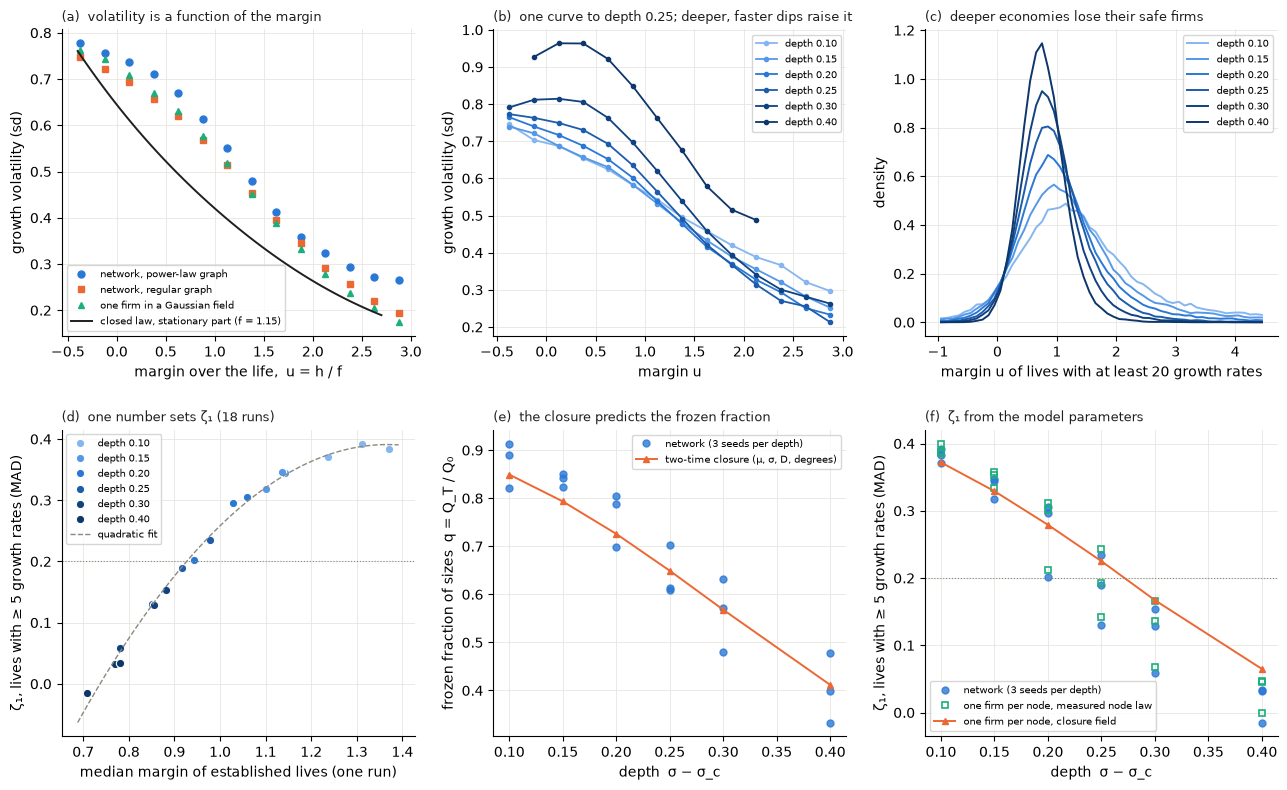

In [14]:
BLUE, ORANGE, AQUA, INK, MUTED, GRID = "#2a78d6", "#eb6834", "#1baf7a", "#1f1f1e", "#8a897f", "#e6e5e0"
RAMP = ["#86b6ef", "#5598e7", "#2a78d6", "#1c5cab", "#104281", "#0d366b"]       # depth 0.10 -> 0.40
fig, ax = plt.subplots(2, 3, figsize=(13, 8)); ax = ax.ravel()
ttl = lambda a, s: a.set_title(s, loc="left", fontsize=9.5, color=INK)
for c, mk, col, lab in ((PL, "o", BLUE, "network, power-law graph"), (REG, "s", ORANGE, "network, regular graph"),
                        (FIX[1.2], "^", AQUA, "one firm in a Gaussian field")):
    x, y = vcurve(c); ax[0].plot(x, y, mk, color=col, ms=5, label=lab)
uu = np.linspace(-0.4, 2.7, 100)
ax[0].plot(uu, [np.sqrt(V2(x, 1.15)) for x in uu], color=INK, lw=1.4, label="closed law, stationary part (f = 1.15)")
ax[0].set(xlabel="margin over the life,  u = h / f", ylabel="growth volatility (sd)"); ax[0].legend(fontsize=7.5, loc="lower left")
ttl(ax[0], "(a)  volatility is a function of the margin")
for col, d in zip(RAMP, DEPTHS):
    c = {k: np.concatenate([LV[d, s][k] for s in DEPTH_SEEDS]) for k in ("n", "u", "sd")}
    x, y = vcurve(c); ax[1].plot(x, y, "-o", color=col, ms=3, lw=1.3, label=f"depth {d:.2f}")
    h, e = np.histogram(c["u"][c["n"] >= 20], bins=np.linspace(-1, 4.5, 56), density=True)
    ax[2].plot(0.5 * (e[1:] + e[:-1]), h, color=col, lw=1.4, label=f"depth {d:.2f}")
    k = RUN[:, 0] == d
    ax[3].plot(RUN[k, 2], RUN[k, 3], "o", color=col, ms=6, mec="white", mew=0.8, label=f"depth {d:.2f}")
ax[1].set(xlabel="margin u", ylabel="growth volatility (sd)"); ax[1].legend(fontsize=7.5)
ttl(ax[1], "(b)  one curve to depth 0.25; deeper, faster dips raise it")
ax[2].set(xlabel="margin u of lives with at least 20 growth rates", ylabel="density"); ax[2].legend(fontsize=7.5)
ttl(ax[2], "(c)  deeper economies lose their safe firms")
xx = np.linspace(RUN[:, 2].min() - 0.02, RUN[:, 2].max() + 0.02, 50)
ax[3].plot(xx, np.polyval(np.polyfit(RUN[:, 2], RUN[:, 3], 2), xx), color=MUTED, lw=1, ls="--", label="quadratic fit")
ax[3].axhline(0.2, color=MUTED, lw=0.8, ls=":")
ax[3].set(xlabel="median margin of established lives (one run)", ylabel="ζ₁, lives with ≥ 5 growth rates (MAD)")
ax[3].legend(fontsize=7, loc="upper left"); ttl(ax[3], "(d)  one number sets ζ₁ (18 runs)")
ax[4].plot(RUN[:, 0], NLR[:, 2], "o", color=BLUE, ms=5, alpha=0.8, label="network (3 seeds per depth)")
ax[4].plot(DEPTHS, [float(np.load(closure_panel(d))["q"]) for d in DEPTHS], "-^", color=ORANGE, ms=5, lw=1.4,
           label="two-time closure (μ, σ, D, degrees)")
ax[4].set(xlabel="depth  σ − σ_c", ylabel="frozen fraction of sizes  q = Q_T / Q₀"); ax[4].legend(fontsize=7.5)
ttl(ax[4], "(e)  the closure predicts the frozen fraction")
ax[5].plot(RUN[:, 0], RUN[:, 3], "o", color=BLUE, ms=5, alpha=0.8, label="network (3 seeds per depth)")
ax[5].plot(RUN[:, 0], NLR[:, 5], "s", color=AQUA, ms=4, mfc="none", mew=1.2, label="one firm per node, measured node law")
ax[5].plot(DEPTHS, [zeta(CL[d]["Sbar"][CL[d]["n"] >= 5], CL[d]["v"][CL[d]["n"] >= 5])[0] for d in DEPTHS], "-^",
           color=ORANGE, ms=5, lw=1.4, label="one firm per node, closure field")
ax[5].axhline(0.2, color=MUTED, lw=0.8, ls=":")
ax[5].set(xlabel="depth  σ − σ_c", ylabel="ζ₁, lives with ≥ 5 growth rates (MAD)"); ax[5].legend(fontsize=7.5, loc="lower left")
ttl(ax[5], "(f)  ζ₁ from the model parameters")
for a in ax:
    a.grid(color=GRID, lw=0.6); a.set_axisbelow(True)
    for sp in ("top", "right"):
        a.spines[sp].set_visible(False)
fig.tight_layout(h_pad=2.2, w_pad=1.8)
plt.show()

## What is open

- **The closure's field.** At the reference point the closure predicts $\zeta_1\simeq0.26$ against 0.21, with almost no
  bend: a Gaussian closure has no spread of field amplitudes at equal degree, and its field moves a little too smoothly.
  Deeper in the phase the field is much too smooth. A closure that keeps the amplitude spread (the cavity method by
  population dynamics) is the next step.
- **Small graphs.** At $N=8000$ the configuration graph loses many hub stubs, so the depth runs are a somewhat
  different economy; the scatter between economies at fixed parameters is also large ($q$ from 0.58 to 0.78).
- **The window.** $q$ counts motion slower than the window as frozen. These runs use a window of 240; on the reference
  economies (window 480) the closure's moving part was 25% low (notebook 07).
- **The levels.** The law runs 3–13% low by size fifth. It leaves out the recovery after a dip, which is a second
  birth inside the life, and its birth term uses $\bar S$ as the target that the newborn chases.
- **The estimator.** The law is for the growth standard deviation. The panel's MAD estimator gives slightly different
  exponents, and the short lives of the $n\ge5$ panel are outside the law.